# Capstone: does Ala-Ala survive concentrated sulfuric acid?

Venus's clouds are droplets of concentrated sulfuric acid, so any molecule that life there might use
has to survive it. Here you test two small peptides with real 1H NMR spectra recorded over four
months in 98% acid:

* **Ala-Ala** is the case you solve.
* **Gly-Gly** is the comparison, worked through for you.

| Part | What you do | Time |
|---|---|---|
| 0 | Predict the spectra from the structures | 10 min |
| 1 | Load the spectra in time order and stack them | 15 min |
| 2 | Compare 1 day with 4 months | 20 min |
| 3 | Write your verdict | 10 min |
| 4 | Compare your verdict with the published finding | 5 min |

Run the cells in order (Shift+Enter). Cells headed **Your turn** need your input.

Data: Petkowski, M. D. Seager, Bains and S. Seager, Zenodo [10.5281/zenodo.11223995](https://doi.org/10.5281/zenodo.11223995), CC BY 4.0. Paper: *Scientific Reports* 14, 17083 (2024).

In [1]:
# Setup. In Colab this first installs the training package (about 30 seconds).
import importlib.util, os
if importlib.util.find_spec("nmrtrain") is None:
    %pip install -q "nmrtrain @ git+https://github.com/Rakiura-Inc/morning-star-nmr@main"
import matplotlib.pyplot as plt
import nmrtrain as nt

NOTEBOOK = "notebooks/01_capstone_ala_ala_vs_gly_gly.ipynb"
MODE = nt.portal.connect(NOTEBOOK)

Offline mode: progress is kept in handin/rakiura_progress.json.


## Part 0: Predict

A dipeptide is two amino acids joined by a peptide bond. In this acid the amine end carries an
extra H (H3N+). Protons on N and O swap with the deuterated acid, so count only the C-H protons.

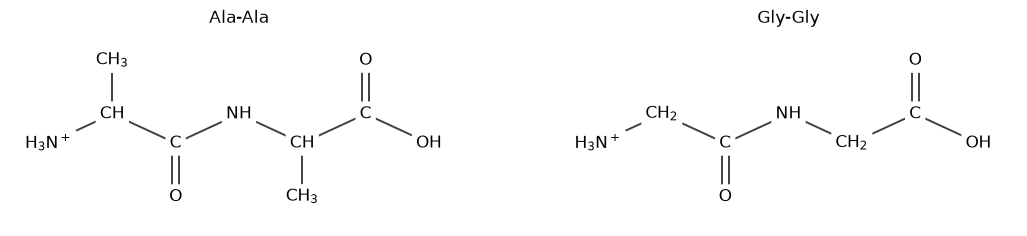

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
nt.plot.draw_dipeptide(axes[0], "Ala", "Ala-Ala")
nt.plot.draw_dipeptide(axes[1], "Gly", "Gly-Gly")
plt.show()

**Your turn**

Use the two structures above to predict the spectra. In the next cell, replace each `...` with
your answer and run it:

* How many C-H signals each peptide gives
* Roughly where the Ala-Ala methyl (CH3) and alpha-H signals sit, in ppm (the position of a peak along the axis)
* Roughly where the Gly-Gly CH2 signals sit, in ppm
* Which peptide breaks down within four months

Leave `...` in place for any you want to skip.

In [3]:
MY_PREDICTION = {
    "AA_signals": ...,      # how many C-H signals does Ala-Ala give?
    "AA_methyl_ppm": ...,   # roughly where are its methyl (CH3) signals, in ppm?
    "AA_alpha_ppm": ...,    # and its alpha-H (the H next to the C=O)?
    "GG_signals": ...,      # how many C-H signals does Gly-Gly give?
    "GG_ch2_ppm": ...,      # roughly where are its CH2 signals?
    "breaks_down": ...,     # which breaks down in 4 months: "Ala-Ala", "Gly-Gly", "both", "neither" or "unsure"?
}
nt.record.predict("capstone", MY_PREDICTION)

Fill in at least one prediction above (replace the ...), then run this cell again.


In [4]:
# Reveal: runs only after you predicted.
if nt.record.revealed("capstone"):
    key = nt.answers.load("capstone", quiet=True)
    nt.checks.check_prediction(MY_PREDICTION, key["prediction"]).show("Your predictions")
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
    nt.plot.draw_dipeptide(axes[0], "Ala", "Ala-Ala: 4 C-H environments",
                           {"S1": ("a", "#f6c9a8"), "S2": ("b", "#f6c9a8"), "A1": ("c", "#b9d7f0"), "A2": ("d", "#b9d7f0")})
    nt.plot.draw_dipeptide(axes[1], "Gly", "Gly-Gly: 2 C-H environments", {"A1": ("a", "#c8e6c3"), "A2": ("b", "#c8e6c3")})
    plt.show()
    print("Two of each, because the two residues are not equivalent: one sits at the H3N+ end, the other at the COOH end.")
    print("The acid pulls electrons away from the protons, so every signal sits about half a ppm higher than in water.")
    nt.portal.done("capstone-predict")

Make your prediction in the cell above first.


## Part 1: Load and look

Each spectrum is one zip file from a 400 MHz spectrometer, already processed by the instrument.
The next cell downloads the ten you need (about 5 MB) and lists them by file name.

In [5]:
aa_paths = nt.data.fetch("11223995", "AA", acid="K", nucleus="1H")
by_time = {nt.data.member_for(p)["time_group"]: p for p in aa_paths}
print("\nSorted by file name:")
for p in sorted(aa_paths):
    print("   ", os.path.basename(p))

AA 1H 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.

Sorted by file name:
    SZSSea-AA-K-1day-1H-07212023_2.zip
    SZSSea-AA-K-3day-1H-07232023_1.zip
    SZSSea-AA-K-4Month-1H-11272023_1.zip
    SZSSea-AA-K-5week-1H-08262023_1.zip
    SZSSea-AA-K-8day-1H-07282023_1.zip


### Trap: loading order

Sorting the labels as text does not put them in time order: `4Month` lands before `5week` and `8day`.

**Your turn**

In the next cell, replace `sorted(by_time)` with a list of the time labels in time order, first
to last. The labels are `"1day"`, `"3day"`, `"8day"`, `"5week"`, `"4Month"`.

In [6]:
AA_ORDER = sorted(by_time)   # change this: sorting the labels as text puts them out of order

In [7]:
aa = [nt.load_processed(by_time[t]) for t in AA_ORDER]
print(nt.checks.check_order(aa))
for s in aa:
    print(f"   {s.time_label:9s} recorded {s.acquired:%Y-%m-%d}   folder {s.folder}")

[trap] Your stack is not in time order: 4 months comes before 5 weeks. Put the spectra in time order before comparing.
   1 day     recorded 2023-07-21   folder SZSSea-AA-K-1day-1H-07212023
   3 days    recorded 2023-07-23   folder SZSSea-AA-K-3day-1H-07212023
   4 months  recorded 2023-11-27   folder SZSSea-AA-K-4Month-1H-11272023
   5 weeks   recorded 2023-08-26   folder SZSSea-AA-K-5week-1H-08262023
   8 days    recorded 2023-07-28   folder SZSSea-AA-K-8day-1H-07282023


The acquisition date comes from the instrument. The folder names were typed by hand and some
carry the wrong date, so go by the instrument's date.

### Trap: a mirrored axis

NMR plots put high ppm on the left. The tallest signal by far is the acid, near **11.5 ppm** in
98% acid. If it sits near 0.5 ppm instead, the axis is reversed and every reading after that is
wrong, with no error message.

In [8]:
for s in aa:
    print(nt.checks.check_axis(s))
print(nt.checks.check_drift(aa))

[ok] Ala-Ala in 98%, 1 day: acid peak at 11.433 ppm. The axis is the right way round.
[ok] Ala-Ala in 98%, 3 days: acid peak at 11.444 ppm. The axis is the right way round.
[ok] Ala-Ala in 98%, 4 months: acid peak at 11.501 ppm. The axis is the right way round.
[ok] Ala-Ala in 98%, 5 weeks: acid peak at 11.479 ppm. The axis is the right way round.
[ok] Ala-Ala in 98%, 8 days: acid peak at 11.472 ppm. The axis is the right way round.
[ok] The acid peak moves by 0.07 ppm across the series, which is small. Keep the instrument's ppm scale.


The acid signal moves up slightly over four months, in both peptides.
Keep the instrument's ppm scale. Do not shift the spectra to line up the acid peak.

### The stack: Gly-Gly, worked

The next cell stacks the five Gly-Gly time points, oldest at the bottom. Each trace is scaled to
its tallest peak between 1 and 6.5 ppm, so the acid signal runs off the top.

GG 1H 98% w/w D2SO4: 5 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.


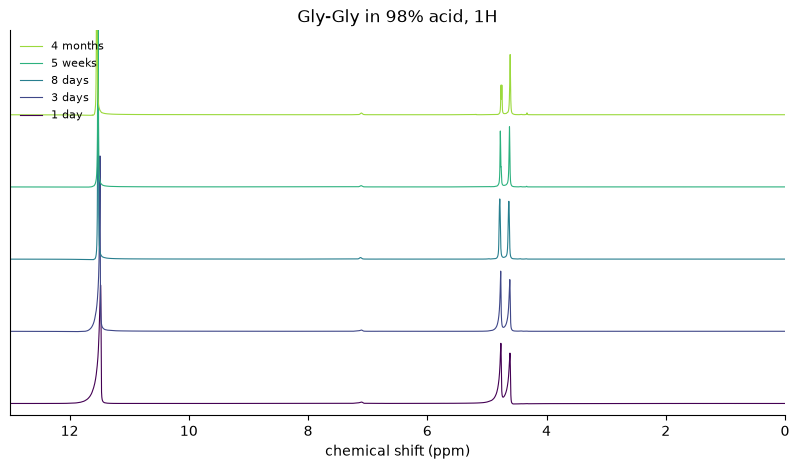

In [9]:
gg = nt.load_series("11223995", "GG", acid="K", nucleus="1H")
fig_gg, ax = nt.plot.stack(gg, 0, 13, norm=(1.0, 6.5), title="Gly-Gly in 98% acid, 1H")
plt.show()

**Your turn**

Stack Ala-Ala the same way. `NORM` is the ppm region each trace is scaled to. `None` scales to the
whole spectrum.

1. Run the cell once with `NORM = None` and read the checks it prints.
2. Set `NORM` to the region you will read, for example `(1.0, 6.5)`, and run it again.

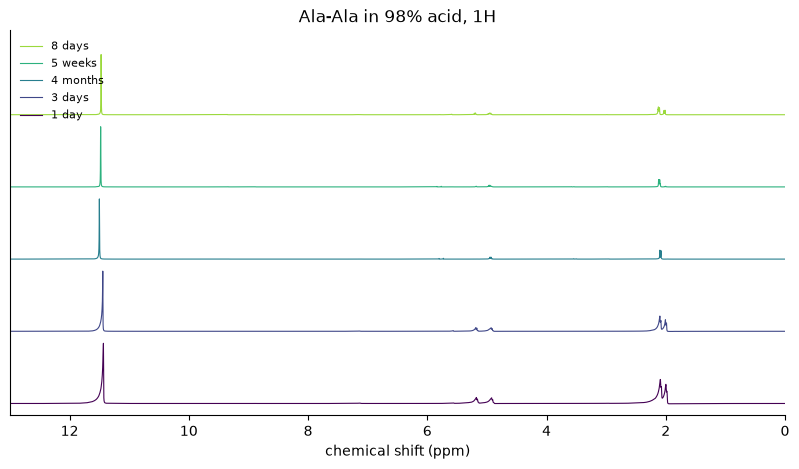

Checks on Ala-Ala in 98% acid: 7 passed, 3 flagged
  [trap] Your stack is not in time order: 4 months comes before 5 weeks. Put the spectra in time order before comparing.
  [trap] Your traces are scaled to the acid peak, which hides small changes. Scale within 1 to 6.5 ppm, or within the region you are reading.
  [note] The 1 day peaks are broader than later ones (15.2 Hz vs 4.1 Hz near 2.09 ppm). This is common while the sample dissolves and is not a chemical change by itself.
rakiura: capstone-stack done, 1 figure(s) (offline log)


In [10]:
NORM = None   # change this: the ppm region to scale within, for example (1.0, 6.5)

fig_aa, ax = nt.plot.stack(aa, 0, 13, norm=NORM, title="Ala-Ala in 98% acid, 1H")
plt.show()
traps_aa = nt.checks.run_traps(aa, norm=NORM)
nt.portal.done("capstone-stack", figures=[fig_aa]);

## Part 2: Compare 1 day and 4 months

The next cell overlays the first and last spectrum of each peptide, zoomed to 1 to 6.5 ppm where
all the C-H signals are, and marks the peaks it finds. `MIN_HEIGHT` is the smallest peak it marks,
as a fraction of the tallest.

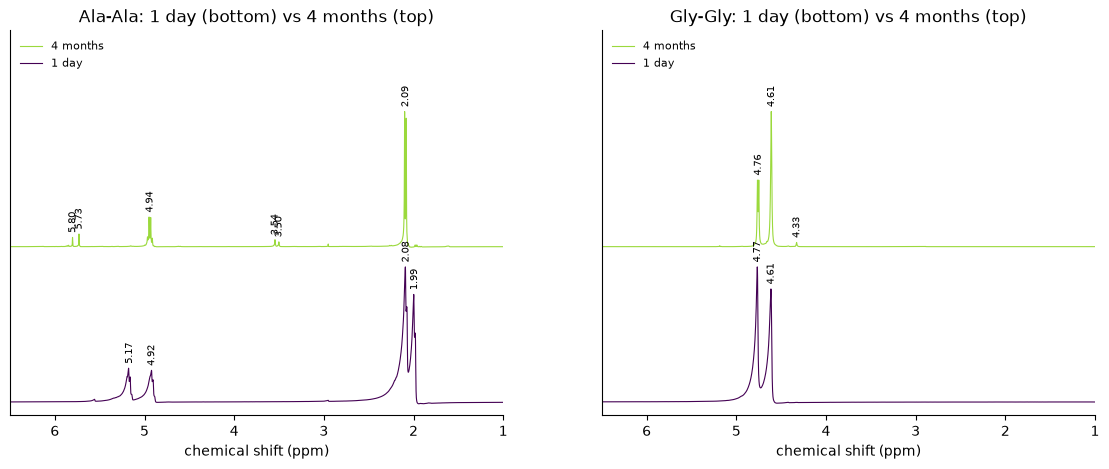

AA {'kept': [4.92, 2.08], 'lost': [5.17, 1.99], 'new': [5.8, 5.73, 3.54, 3.5]}
GG {'kept': [4.77, 4.61], 'lost': [], 'new': [4.33]}


In [11]:
MIN_HEIGHT = 0.03   # try 0.10: which peaks would you miss?

aa_t = {s.time: s for s in aa}
gg_t = {s.time: s for s in gg}
my_peaks = {}
for name, t in (("AA", aa_t), ("GG", gg_t)):
    my_peaks[name] = {k: nt.peaks.pick(t[k], 1.0, 6.5, MIN_HEIGHT) for k in ("1day", "4Month")}

fig_zoom, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name, t in ((axes[0], "AA", aa_t), (axes[1], "GG", gg_t)):
    nt.plot.compare(t["1day"], t["4Month"], peaks_first=my_peaks[name]["1day"],
                    peaks_last=my_peaks[name]["4Month"], ax=ax)
plt.show()
for name in ("AA", "GG"):
    print(name, {k: [round(p, 2) for p in v] for k, v in nt.peaks.compare(*my_peaks[name].values()).items()})

Intact Ala-Ala has **two** methyl doublets (near 1.99 and 2.08 ppm) and **two** alpha-H signals
(near 4.92 and 5.17 ppm), one of each per residue. Check which of the four are left at 4 months.
A peak in the same place is not proof that the same molecule is still there.

### Trap: broad early peaks

At 1 day every peak is broad, in both peptides, while the sample is still settling in the acid.
The positions do not change and Gly-Gly broadens too, so it is not a new molecule.

In [12]:
for s in gg:
    pos, width = nt.peaks.linewidth_hz(s, 4.62)
    print(f"Gly-Gly {s.time_label:9s} peak at {pos:.3f} ppm, {width:4.1f} Hz wide")
nt.portal.done("capstone-compare", figures=[fig_zoom]);

Gly-Gly 1 day     peak at 4.614 ppm, 10.8 Hz wide
Gly-Gly 3 days    peak at 4.616 ppm,  9.0 Hz wide
Gly-Gly 8 days    peak at 4.633 ppm,  9.2 Hz wide
Gly-Gly 5 weeks   peak at 4.622 ppm,  5.9 Hz wide
Gly-Gly 4 months  peak at 4.610 ppm,  5.7 Hz wide
rakiura: capstone-compare done, 1 figure(s) (offline log)


## Part 3: Your verdict

**Your turn**

Decide whether each peptide survives four months in 98% acid. Fill in both entries in the next
cell, using ppm values from your peak lists in Part 2:

* `call`: `"survives"`, `"degrades"`, or `"unsure"` if the data do not settle it
* `lost_ppm`: signals present at 1 day and gone at 4 months
* `new_ppm`: signals that appear by 4 months
* `kept_ppm`: signals present at both times
* `product_guess`: the main product in words, or `"none"`
* `confidence`: `"low"`, `"medium"` or `"high"`

Before you decide, check:

* Are both members of each pair still there?
* Has anything new appeared, even a small peak?
* If one residue broke off, what would the other become?

In [13]:
MY_VERDICT = {
    "AA": {"call": "", "lost_ppm": [], "new_ppm": [], "kept_ppm": [], "product_guess": "", "confidence": ""},
    "GG": {"call": "", "lost_ppm": [], "new_ppm": [], "kept_ppm": [], "product_guess": "", "confidence": ""},
    "note": "",   # anything you want your reviewer to know
}
problems = nt.checks.verdict_problems(MY_VERDICT, ["AA", "GG"])
print("\n".join(problems) or "Verdict format OK.")

Verdict format OK.


## Part 4: Compare with the published finding

The next cell compares your call with the published finding (Petkowski et al. 2024, *Scientific
Reports* 14, 17083) and your product guess with the mechanism study. It flags a cited value that is
the acid's own signal. It does not read your reasoning in words, and it does not grade. Your
reviewer reads the ppm values you cite.

In [14]:
feedback = {}
if nt.record.revealed("capstone"):
    key = nt.answers.load("capstone")
    for case in ("AA", "GG"):
        c = nt.answers.case(key, case)
        feedback[case] = nt.checks.check_verdict(MY_VERDICT[case], c).show(f"{case}: your verdict")

Make your prediction in the cell above first.


### Look closer (optional): the product's own spectrum

The mechanism study recorded the suspected product, L-alaninamide, in the same acid. The next cell
lays its spectrum over Ala-Ala at 4 months. Check whether the new peaks line up with it.

LAlaninamide 1H both acids: 1 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Grimes Jr, J. H.; Seager, S. (2024). Mechanism for Peptide Bond Solvolysis in 98% w/w Concentrated Sulfuric Acid (Supplementary datasets 1 to 5). Zenodo. https://doi.org/10.5281/zenodo.11122291 (CC BY 4.0). Paper: Petkowski et al. 2024, ACS Omega (peptide bond solvolysis mechanism).


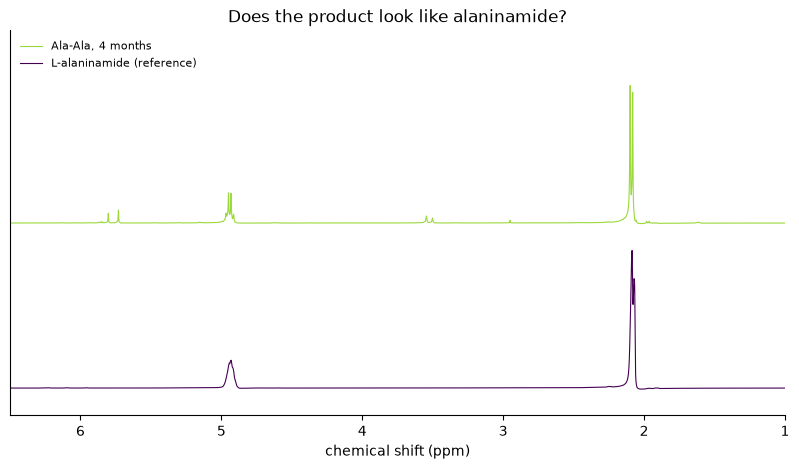

alaninamide peaks: [4.931, 2.079]


In [15]:
ref = nt.load_processed(nt.data.fetch("11122291", "LAlaninamide", acid=None, nucleus="1H")[0])
fig_ref, ax = nt.plot.stack([ref, aa_t["4Month"]], 1.0, 6.5, norm=(1.0, 6.5),
                            labels=["L-alaninamide (reference)", "Ala-Ala, 4 months"],
                            title="Does the product look like alaninamide?")
plt.show()
print("alaninamide peaks:", [p["ppm"] for p in nt.peaks.pick(ref, 1.0, 6.5, 0.1)])

## Hand-in

The next cell saves these in `handin/` and ticks the step:

* the Ala-Ala and Gly-Gly stacks
* the 1 day vs 4 months comparison
* `verdict.json`, with your verdict, peak lists and feedback

Nothing is sent for review. When you are ready, run `nt.portal.submit()` or submit from the step page.

In [16]:
record = nt.record.handin(
    "capstone-verdict",
    figures={"stack_AA": fig_aa, "stack_GG": fig_gg, "zoom_1day_vs_4months": fig_zoom},
    verdict={"verdict": MY_VERDICT, "my_peaks_ppm": {k: {t: nt.peaks.ppms(v) for t, v in d.items()} for k, d in my_peaks.items()},
             "feedback": {k: [str(f) for f in v] for k, v in feedback.items()}},
    numbers={"AA_call": MY_VERDICT["AA"]["call"] or "blank", "GG_call": MY_VERDICT["GG"]["call"] or "blank",
             "AA_product": MY_VERDICT["AA"]["product_guess"] or "blank",
             "AA_confidence": MY_VERDICT["AA"]["confidence"] or "blank", "min_height": MIN_HEIGHT},
    question="capstone",
    traps=nt.checks.traps_flagged(traps_aa),
)
# nt.portal.submit()   # when you are ready: sends this step for review

rakiura: capstone-verdict done, 3 figure(s), 9 number(s) (offline log)
Saved for your hand-in:
   handin/capstone-verdict/stack_AA.png
   handin/capstone-verdict/stack_GG.png
   handin/capstone-verdict/zoom_1day_vs_4months.png
   handin/capstone-verdict/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.
